# Project 4: Customer Segmentation with RFM and K-Means (ShopSphere)

**Folder:** `27_pandas/project/` | **Level:** Intermediate | **Time:** 3 hours | **Libraries:** NumPy, pandas, Matplotlib (no scikit-learn needed)

## The business problem

ShopSphere is an online store with about 2,500 registered customers. The marketing team sends the **same email to everyone**: the same discount, the same newsletter. Results are poor, because a customer who orders twice a month, a customer who bought once in the sale and vanished, and a shop that buys 40 units at a time are very different people.

> **Who are our customers, what do the different groups look like, and what should we do for each group?**

This is **unsupervised learning**: there is no label to predict. We **discover groups** in the data, then turn them into **business actions**.

## What you will build

1. Clean a **messy transaction export** (cancellations, guest checkouts, free items, test rows, typing mistakes)
2. Turn 75,000 rows into **one row per customer** with RFM features (Recency, Frequency, Monetary) and more
3. Prepare the features properly (**log transform, standardise, PCA with SVD**)
4. Write **K-Means from scratch in NumPy** (k-means++ start, many restarts, broadcasting distances)
5. Choose the number of groups with the **elbow, the silhouette score** (also from scratch) and a **stability check** (adjusted Rand index from scratch)
6. **Profile and name** the segments and compare them with the classic **RFM-score** method
7. Estimate the **revenue at stake** and propose an action per segment

## Skills map

| Skill | Where | Theory notebook |
|---|---|---|
| Cleaning: duplicates, date formats, non-product rows, impossible prices | data cleaning | 07, 08 |
| `groupby` with named aggregation, `diff` for gaps between orders, `pivot_table` for category shares | customer features | 10, 12 |
| `merge(validate=)`, `qcut`, `crosstab`, `pd.Grouper` | products, RFM scores, timeline | 09, 11, 12, 13 |
| NumPy: broadcasting distance matrices, `argmin`, `svd`, `linalg`, boolean masks, `random.default_rng` | K-Means, PCA, silhouette | 26_numpy |
| Matplotlib: scatter, stackplot, heatmap with `imshow`, twin lines, Pareto curve | all charts | 15 |
| ML ideas: scaling, skew, curse of scale, choosing k, cluster stability, profiling | the whole project | - |

---
# 0. Setup

In [32]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 150)

PROJECT = "project_4_customer_segmentation_rfm"
DATA = Path("data") / PROJECT
FIG = Path("figures") / PROJECT
DATA.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

SEED = 31
SNAPSHOT = pd.Timestamp("2026-07-01")          # "today": the day after the last order in the data

plt.rcParams.update({
    "figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "axes.titlesize": 12, "axes.titleweight": "bold",
})

def savefig(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")

print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 3.0.6 | numpy 2.5.3


---
# 1. The raw data

A seeded simulator creates a realistic order export. Customers belong (secretly) to behaviour types such as *champions*, *loyal*, *new*, *at risk*, *bargain hunters*, *wholesale* and *one-time buyers*. **The algorithm never sees these types.** At the very end we peek at them, to check whether K-Means rediscovered the structure (in real life you cannot do that check).

If you have a real dataset (for example the public "Online Retail" transactions) you can load it in section 1.2 and adapt the column names.

In [33]:
CATEGORIES = ['Electronics', 'Fashion', 'Home', 'Beauty', 'Grocery', 'Toys']
CAT_PRICE = {'Electronics': 2200, 'Fashion': 900, 'Home': 650, 'Beauty': 450, 'Grocery': 180, 'Toys': 500}
SALE_PERIODS = [('2025-11-20', '2025-11-30'), ('2026-01-20', '2026-01-31')]
SEGMENTS = {'champion': (0.12, 2.0, 4.0, 1.6, 1.2, 0.03), 'loyal': (0.23, 0.9, 3.0, 1.4, 1.0, 0.04), 'new': (0.15, 1.5, 3.0, 1.3, 0.9, 0.04), 'at_risk': (0.18, 1.2, 3.5, 1.4, 1.1, 0.05), 'bargain': (0.24, 1.0, 2.0, 1.2, 0.45, 0.08), 'wholesale': (0.03, 0.35, 6.0, 20.0, 0.6, 0.02), 'one_time': (0.05, 0.0, 2.5, 1.3, 1.0, 0.05)}

def make_shopsphere(seed=31, n_customers=2500):
    rng = np.random.default_rng(seed)
    start, end = pd.Timestamp("2025-07-01"), pd.Timestamp("2026-06-30")
    names = list(SEGMENTS)
    probs = np.array([SEGMENTS[k][0] for k in names]); probs = probs / probs.sum()
    seg = rng.choice(names, n_customers, p=probs)
    cust_id = rng.choice(np.arange(10000, 99999), n_customers, replace=False)

    # product catalogue
    n_prod = 120
    p_cat = rng.choice(CATEGORIES, n_prod)
    products = pd.DataFrame({
        "stock_code": [f"P{i:04d}" for i in range(n_prod)],
        "description": [f"{c} item {i}" for i, c in enumerate(p_cat)],
        "category": p_cat,
        "base_price": [round(CAT_PRICE[c] * rng.lognormal(0, 0.45)) for c in p_cat],
    })
    by_cat = {c: np.where(p_cat == c)[0] for c in CATEGORIES}

    sale_days = pd.DatetimeIndex(np.concatenate([pd.date_range(a, b) for a, b in SALE_PERIODS]))
    rows, order_no = [], 100000
    truth = []
    for cid, sg in zip(cust_id, seg):
        share, lam, lines_m, qty_m, pmult, cancel_p = SEGMENTS[sg]
        if sg == "new":
            first = start + pd.Timedelta(days=int(rng.integers(305, 360)))
            window = (first, end)
        elif sg == "at_risk":
            window = (start, pd.Timestamp("2025-09-01") + pd.Timedelta(days=int(rng.integers(0, 122))))
        elif sg == "one_time":
            first = start + pd.Timedelta(days=int(rng.integers(0, 240)))
            window = (first, first)
        else:
            window = (start, end)
        months = max((window[1] - window[0]).days / 30.4, 0.2)
        n_orders = 1 if sg == "one_time" else max(1, rng.poisson(lam * months))
        if sg == "new":
            n_orders = max(1, rng.poisson(lam * months))
        span = (window[1] - window[0]).days
        days = np.sort(rng.integers(0, max(span, 1), n_orders)) if sg != "one_time" else np.array([0])
        dates = window[0] + pd.to_timedelta(days, unit="D")
        if sg == "new":
            dates = dates.where(np.arange(n_orders) > 0, window[0])               # the first order is the first day
        if sg == "bargain":
            pick = rng.random(n_orders) < 0.6
            dates = pd.DatetimeIndex([rng.choice(sale_days) if p else d for p, d in zip(pick, dates)])
        pref = rng.dirichlet(np.ones(len(CATEGORIES)) * (0.5 if sg != "wholesale" else 3.0))
        for d in dates:
            order_no += 1
            n_lines = 1 + rng.poisson(lines_m - 1)
            cats = rng.choice(CATEGORIES, n_lines, p=pref)
            prod_idx = np.array([rng.choice(by_cat[c]) if len(by_cat[c]) else 0 for c in cats])
            qty = 1 + rng.poisson(qty_m - 1, n_lines) if sg != "wholesale" else 10 + rng.poisson(qty_m, n_lines)
            price = np.round(products["base_price"].to_numpy()[prod_idx] * pmult * (0.8 if d in sale_days else 1.0) * rng.lognormal(0, 0.05, n_lines))
            ts = d + pd.Timedelta(hours=int(rng.integers(8, 23)), minutes=int(rng.integers(0, 60)))
            for k in range(n_lines):
                rows.append((f"{order_no}", products["stock_code"].iloc[prod_idx[k]], int(qty[k]), ts, float(price[k]), cid))
            if rng.random() < cancel_p:                                           # a cancellation of part of the order, days later
                ck = rng.integers(0, n_lines)
                rows.append((f"C{order_no}", products["stock_code"].iloc[prod_idx[ck]], -int(qty[ck]), ts + pd.Timedelta(days=int(rng.integers(1, 10))),
                             float(price[ck]), cid))
        truth.append((cid, sg))

    tx = pd.DataFrame(rows, columns=["invoice_no", "stock_code", "quantity", "invoice_date", "unit_price", "customer_id"])
    tx = tx[tx["invoice_date"] <= end + pd.Timedelta(days=1)]

    # guest checkouts (no customer id): extra anonymous orders
    g_rows = []
    for _ in range(1400):
        order_no += 1
        d = start + pd.Timedelta(days=int(rng.integers(0, 365)), hours=int(rng.integers(8, 23)), minutes=int(rng.integers(0, 60)))
        for _ in range(1 + rng.poisson(1.5)):
            i = rng.integers(0, n_prod)
            g_rows.append((f"{order_no}", products["stock_code"].iloc[i], int(1 + rng.poisson(0.4)), d, float(round(products["base_price"].iloc[i])), np.nan))
    tx = pd.concat([tx, pd.DataFrame(g_rows, columns=tx.columns)], ignore_index=True)

    # ---------- real-world mess ----------
    tx = tx.merge(products[["stock_code", "description"]], on="stock_code", how="left")
    junk = pd.DataFrame({
        "invoice_no": [f"{900000 + i}" for i in range(60)],
        "stock_code": rng.choice(["POST", "TEST001", "ADJUST"], 60), "quantity": 1,
        "invoice_date": start + pd.to_timedelta(rng.integers(0, 365, 60), unit="D"),
        "unit_price": rng.choice([150.0, 0.0, -300.0], 60), "customer_id": np.nan, "description": "SERVICE ROW"})
    tx = pd.concat([tx, junk], ignore_index=True)
    tx.loc[rng.random(len(tx)) < 0.004, "unit_price"] = 0.0                      # free samples / data errors
    typo = rng.choice(len(tx), 5, replace=False)
    tx.loc[typo, "quantity"] = tx.loc[typo, "quantity"].abs() * 1000             # typing mistakes
    fmt = rng.random(len(tx))
    d = pd.to_datetime(tx["invoice_date"])
    tx["invoice_date"] = np.where(fmt < 0.85, d.dt.strftime("%Y-%m-%d %H:%M"), d.dt.strftime("%d/%m/%Y %H:%M"))
    tx["description"] = [x if rng.random() > 0.2 else rng.choice([x.upper(), " " + x, x + "  ", x.lower()]) for x in tx["description"]]
    tx = pd.concat([tx, tx.sample(60, random_state=7)], ignore_index=True)
    tx["customer_id"] = tx["customer_id"].astype("float")
    tx = tx.sample(frac=1, random_state=9).reset_index(drop=True)                # a real export is not sorted
    truth = pd.DataFrame(truth, columns=["customer_id", "true_segment"])
    return tx, products, truth

In [34]:
tx_raw, products, truth = make_shopsphere(seed=SEED)

tx_raw.to_csv(DATA / "transactions_raw.csv", index=False)
products.to_csv(DATA / "products.csv", index=False)
truth.to_csv(DATA / "simulator_truth_DO_NOT_USE_FOR_MODELLING.csv", index=False)     # only for the final sanity check

tx = pd.read_csv(DATA / "transactions_raw.csv", dtype={"invoice_no": "str"})
print(tx.shape)
tx.head()

(77561, 7)


,invoice_no,stock_code,quantity,invoice_date,unit_price,customer_id,description
0,118435,P0089,2,2026-06-29 11:28,711.0,96692.0,Beauty item 89
1,101584,P0088,1,2025-12-12 09:03,344.0,27857.0,Toys item 88
2,116611,P0030,2,2025-08-10 11:40,1460.0,51587.0,Fashion item 30
3,113623,P0063,1,06/02/2026 11:21,2598.0,51401.0,Fashion item 63
4,111877,P0039,1,2026-01-29 15:43,148.0,23631.0,Home item 39


## Data dictionary

| Column | Meaning |
|---|---|
| `invoice_no` | order number. **Starts with `C` for a cancellation** |
| `stock_code`, `description` | product (`POST`, `TEST001`, `ADJUST` are not products) |
| `quantity` | units (negative for cancellations) |
| `invoice_date` | order time (text, two formats) |
| `unit_price` | price per unit in rupees |
| `customer_id` | registered customer (**empty = guest checkout**) |

One row is **one product line of one order**. An order with 3 products has 3 rows.

---
# 2. Look before you clean (chapter 04)

In [35]:
def quick_look(df):
    return pd.DataFrame({"dtype": df.dtypes.astype(str), "missing": df.isna().sum(), "missing_%": (df.isna().mean() * 100).round(1), "unique": df.nunique()})

print("exact duplicate rows:", tx.duplicated().sum())
quick_look(tx)

exact duplicate rows: 72


,dtype,missing,missing_%,unique
invoice_no,str,0,0.0,26589
stock_code,str,0,0.0,123
quantity,int64,0,0.0,46
invoice_date,str,0,0.0,33438
unit_price,float64,0,0.0,4826
customer_id,float64,3510,4.5,2500
description,str,0,0.0,604


In [36]:
print("cancellations (invoice starts with C):", tx["invoice_no"].str.startswith("C").sum())
print("non-product codes:", tx.loc[tx["stock_code"].isin(["POST", "TEST001", "ADJUST"]), "stock_code"].value_counts().to_dict())
print("price <= 0 rows  :", int((tx["unit_price"] <= 0).sum()))
print("date text formats:", tx["invoice_date"].str.contains("/").map({True: "DD/MM/YYYY", False: "YYYY-MM-DD"}).value_counts().to_dict())
print(tx["quantity"].describe().round(1))
print("quantity above 500:", int((tx["quantity"] > 500).sum()))

cancellations (invoice starts with C): 1217
non-product codes: {'ADJUST': 21, 'TEST001': 21, 'POST': 18}
price <= 0 rows  : 332
date text formats: {'YYYY-MM-DD': 65961, 'DD/MM/YYYY': 11600}
count    77561.0
mean         2.1
std         11.0
min        -37.0
25%          1.0
50%          1.0
75%          2.0
max       2000.0
Name: quantity, dtype: float64
quantity above 500: 5


### Problems and decisions

| Problem | Decision |
|---|---|
| 60 duplicate rows | drop |
| `POST`, `TEST001`, `ADJUST` rows | not products: drop |
| price of 0 or negative | free samples or adjustments, no real sale: drop |
| quantity above 500 | typing mistakes (wholesale shops buy tens, not thousands): drop |
| dates in two formats | explicit two-format parsing |
| descriptions in mixed case with spaces | strip and title-case |
| **cancellations** (`C...`, negative quantity) | **keep, but separate**: they reduce a customer's value |
| **guest checkouts** (no `customer_id`) | keep for total revenue, **exclude from customer analysis** (we cannot group them) |

**Say it in an interview:** "Cancellations are real information (returns), so I kept them as negative revenue per customer. Guest checkouts cannot be segmented, so I reported how much revenue they represent and excluded them from the clustering."

# 3. Cleaning

In [37]:
log = []
def note(step, n):
    log.append({"step": step, "rows": int(n)})

t = tx.copy()
note("rows in the raw file", len(t))

# 1. duplicates
before = len(t); t = t.drop_duplicates(); note("exact duplicates removed", before - len(t))

# 2. dates: two explicit formats
d1 = pd.to_datetime(t["invoice_date"], format="%Y-%m-%d %H:%M", errors="coerce")
d2 = pd.to_datetime(t["invoice_date"].where(d1.isna()), format="%d/%m/%Y %H:%M", errors="coerce")
t["invoice_date"] = d1.fillna(d2)
assert t["invoice_date"].notna().all()

# 3. non-product codes, prices <= 0, quantity typos
mask = t["stock_code"].isin(["POST", "TEST001", "ADJUST"]); note("non-product rows removed (POST, TEST, ADJUST)", mask.sum()); t = t[~mask]
mask = t["unit_price"] <= 0; note("price <= 0 removed", mask.sum()); t = t[~mask]
mask = t["quantity"].abs() > 500; note("quantity typing mistakes removed", mask.sum()); t = t[~mask]

# 4. text
t["description"] = t["description"].str.strip().str.title()

# 5. cancellation flag and revenue (negative for cancellations)
t["is_cancel"] = t["invoice_no"].str.startswith("C")
assert (t.loc[t["is_cancel"], "quantity"] < 0).all() and (t.loc[~t["is_cancel"], "quantity"] > 0).all()
t["revenue"] = t["quantity"] * t["unit_price"]

# 6. product category (many rows to one product)
t = t.merge(products[["stock_code", "category"]], on="stock_code", how="left", validate="many_to_one")
assert t["category"].notna().all()

note("rows after cleaning", len(t))
pd.DataFrame(log)

,step,rows
0,rows in the raw file,77561
1,exact duplicates removed,72
2,"non-product rows removed (POST, TEST, ADJUST)",60
3,price <= 0 removed,296
4,quantity typing mistakes removed,5
5,rows after cleaning,77128


In [38]:
# What share of revenue do guests and cancellations represent?
sales = t[~t["is_cancel"]]
total = sales["revenue"].sum()
print(f"revenue from registered customers: {sales.loc[sales['customer_id'].notna(), 'revenue'].sum() / total * 100:.1f}%")
print(f"revenue from guest checkouts     : {sales.loc[sales['customer_id'].isna(), 'revenue'].sum() / total * 100:.1f}%")
print(f"cancelled value as % of sales    : {-t.loc[t['is_cancel'], 'revenue'].sum() / total * 100:.1f}%")

# split into customer lines (what we analyse) and the rest
cl = t[t["customer_id"].notna()].copy()
cl["customer_id"] = cl["customer_id"].astype(int)
print("customer lines:", len(cl), "| customers:", cl["customer_id"].nunique())

revenue from registered customers: 96.1%
revenue from guest checkouts     : 3.9%
cancelled value as % of sales    : 0.9%
customer lines: 73697 | customers: 2500


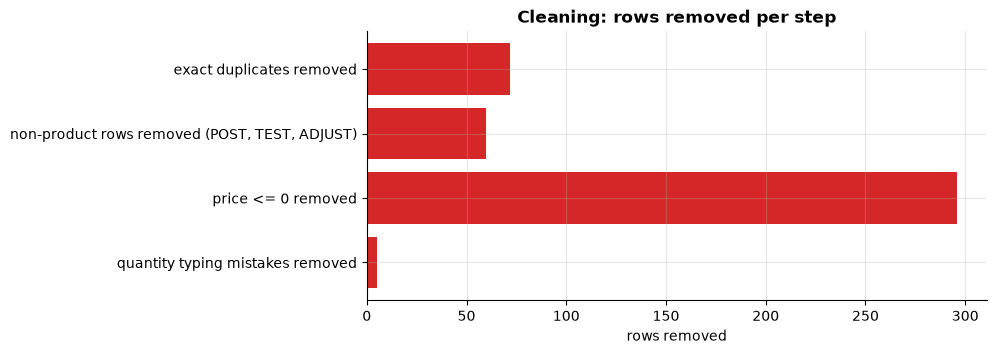

In [39]:
# Chart 1: what did cleaning remove?
steps = pd.DataFrame(log).iloc[1:-1]
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(steps["step"], steps["rows"], color="#d62728")
ax.invert_yaxis(); ax.set_xlabel("rows removed")
ax.set_title("Cleaning: rows removed per step")
plt.show()
savefig(fig, "01_cleaning_log")

---
# 4. Feature engineering: one row per customer

**RFM** is the classic marketing trio:

| Letter | Meaning | Question |
|---|---|---|
| **R**ecency | days since the last order | is the customer still active? |
| **F**requency | number of orders | how often do they buy? |
| **M**onetary | total spend | how much do they spend? |

We add a few more signals: average order value, tenure, average gap between orders, number of categories, **sale share** (orders during sale periods) and **cancellation rate**.

Everything is measured at the **snapshot date** (`2026-07-01`).

In [40]:
purchases = cl[~cl["is_cancel"]]
cancels = cl[cl["is_cancel"]]

# one row per order
orders = purchases.groupby(["customer_id", "invoice_no"]).agg(
    order_date=("invoice_date", "min"), order_value=("revenue", "sum"), units=("quantity", "sum"),
).reset_index().sort_values(["customer_id", "order_date"])

SALE_PERIODS = [("2025-11-20", "2025-11-30"), ("2026-01-20", "2026-01-31")]
orders["in_sale"] = False
for a, b in SALE_PERIODS:
    orders.loc[orders["order_date"].between(a, pd.Timestamp(b) + pd.Timedelta(days=1)), "in_sale"] = True
orders["gap_days"] = orders.groupby("customer_id")["order_date"].diff().dt.total_seconds() / 86400      # days since the previous order

cust = orders.groupby("customer_id").agg(
    last_order=("order_date", "max"), first_order=("order_date", "min"),
    frequency=("invoice_no", "nunique"), monetary=("order_value", "sum"),
    avg_order_value=("order_value", "mean"), avg_units_per_order=("units", "mean"),
    avg_gap_days=("gap_days", "mean"), sale_share=("in_sale", "mean"),
)
cust["recency_days"] = (SNAPSHOT - cust["last_order"]).dt.days
cust["tenure_days"] = (SNAPSHOT - cust["first_order"]).dt.days

# categories: spend share per category (pivot), number of categories bought
cat_spend = purchases.pivot_table(index="customer_id", columns="category", values="revenue", aggfunc="sum", fill_value=0)
cust["n_categories"] = (cat_spend > 0).sum(axis=1)
cust["top_category"] = cat_spend.idxmax(axis=1)

# cancellations
cust["cancelled_value"] = -cancels.groupby("customer_id")["revenue"].sum()
cust["cancelled_value"] = cust["cancelled_value"].fillna(0)
cust["cancel_rate"] = cust["cancelled_value"] / cust["monetary"]
cust["net_value"] = cust["monetary"] - cust["cancelled_value"]
cust["avg_gap_days"] = cust["avg_gap_days"].fillna(cust["tenure_days"])           # one order: no gap, use the tenure

cust = cust.drop(columns=["last_order", "first_order"])
assert cust.index.is_unique and not cust.drop(columns="top_category").isna().any().any()
print(cust.shape)
cust.head()

(2500, 13)


,frequency,monetary,avg_order_value,avg_units_per_order,avg_gap_days,sale_share,recency_days,tenure_days,n_categories,top_category,cancelled_value,cancel_rate,net_value
customer_id,,,,,,,,,,,,,
10026,4,38851.0,9712.750000,3.250000,5.453704,0.000000,320,336,2,Electronics,0.0,0.0,38851.0
10027,6,37457.0,6242.833333,6.166667,21.812639,0.000000,229,338,4,Electronics,0.0,0.0,37457.0
10043,17,125221.0,7365.941176,4.882353,21.425651,0.058824,1,344,4,Electronics,0.0,0.0,125221.0
10074,7,21067.0,3009.571429,3.857143,21.165509,0.000000,233,360,5,Fashion,0.0,0.0,21067.0
10089,3,20913.0,6971.000000,5.000000,44.250694,0.000000,269,357,2,Fashion,0.0,0.0,20913.0


In [41]:
cust[["recency_days", "frequency", "monetary", "avg_order_value", "tenure_days", "sale_share", "cancel_rate"]].describe().round(1)

,recency_days,frequency,monetary,avg_order_value,tenure_days,sale_share,cancel_rate
count,2500.0,2500.0,2500.0,2500.0,2500.0,2500.0,2500.0
mean,93.2,9.6,48852.5,6200.8,278.9,0.2,0.0
std,104.1,7.3,92303.8,17136.1,110.0,0.3,0.1
min,1.0,1.0,35.0,35.0,5.0,0.0,0.0
25%,14.0,3.0,6619.2,1186.0,254.0,0.0,0.0
50%,42.0,9.0,16736.0,2998.7,331.0,0.0,0.0
75%,152.0,13.0,44265.8,5413.5,352.0,0.4,0.0
max,363.0,38.0,1071160.0,260869.0,364.0,1.0,1.0


Notice the scales: `monetary` goes into hundreds of thousands, `frequency` into the dozens, `sale_share` between 0 and 1. K-Means uses **distances**, so a feature with a huge scale would dominate everything. We must **transform and standardise** before clustering (section 6).

# 5. Exploratory analysis

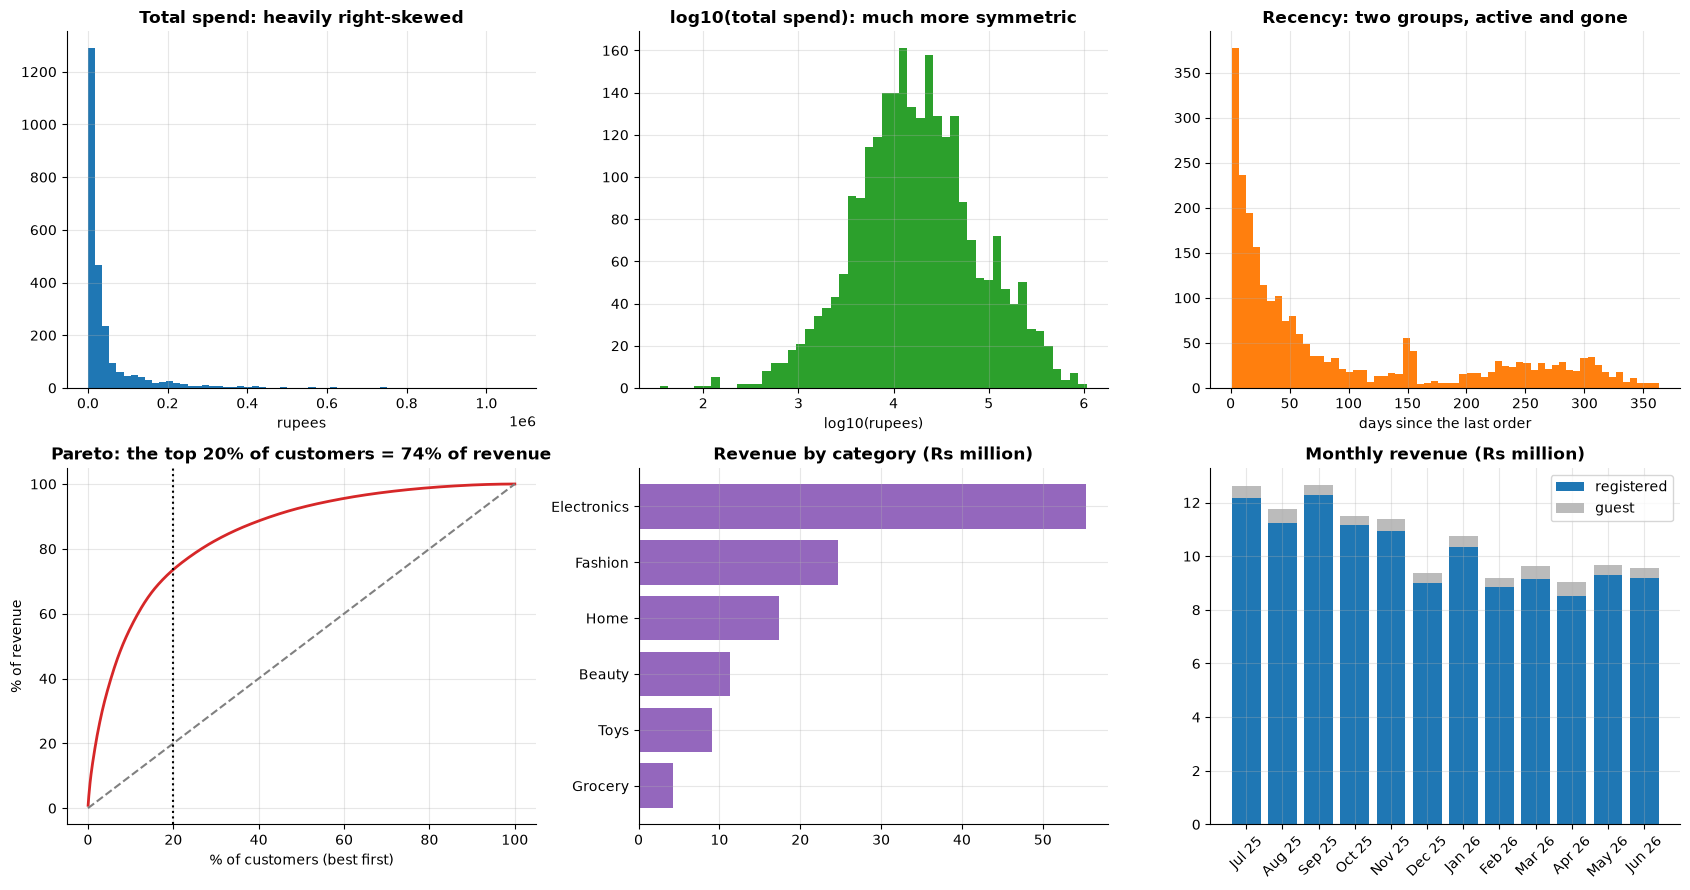

In [42]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9))

axes[0, 0].hist(cust["monetary"], bins=60, color="#1f77b4")
axes[0, 0].set_title("Total spend: heavily right-skewed"); axes[0, 0].set_xlabel("rupees")

axes[0, 1].hist(np.log10(cust["monetary"]), bins=50, color="#2ca02c")
axes[0, 1].set_title("log10(total spend): much more symmetric"); axes[0, 1].set_xlabel("log10(rupees)")

axes[0, 2].hist(cust["recency_days"], bins=60, color="#ff7f0e")
axes[0, 2].set_title("Recency: two groups, active and gone"); axes[0, 2].set_xlabel("days since the last order")

# Pareto curve
s = cust["net_value"].sort_values(ascending=False).to_numpy()
cum = np.cumsum(s) / s.sum() * 100
x = np.arange(1, len(s) + 1) / len(s) * 100
axes[1, 0].plot(x, cum, color="#d62728", linewidth=2)
axes[1, 0].plot([0, 100], [0, 100], "--", color="gray")
top20 = cum[int(len(s) * 0.2) - 1]
axes[1, 0].axvline(20, color="black", linestyle=":")
axes[1, 0].set_title(f"Pareto: the top 20% of customers = {top20:.0f}% of revenue")
axes[1, 0].set_xlabel("% of customers (best first)"); axes[1, 0].set_ylabel("% of revenue")

cat_rev = purchases.groupby("category")["revenue"].sum().sort_values()
axes[1, 1].barh(cat_rev.index, cat_rev.values / 1e6, color="#9467bd")
axes[1, 1].set_title("Revenue by category (Rs million)")

monthly = sales.groupby([pd.Grouper(key="invoice_date", freq="ME"), sales["customer_id"].notna()])["revenue"].sum().unstack() / 1e6      # "sales" still contains the guest checkouts
monthly.columns = ["guest", "registered"]
axes[1, 2].bar(monthly.index.strftime("%b %y"), monthly["registered"], color="#1f77b4", label="registered")
axes[1, 2].bar(monthly.index.strftime("%b %y"), monthly["guest"], bottom=monthly["registered"], color="#bbbbbb", label="guest")
axes[1, 2].set_title("Monthly revenue (Rs million)"); axes[1, 2].legend(); axes[1, 2].tick_params(axis="x", rotation=45)

plt.tight_layout(); plt.show()
savefig(fig, "02_eda_overview")

**What we learned:**
- **Heavy skew** (a few huge customers): we will log-transform.
- **Pareto principle**: a small share of customers produces most of the revenue. The marketing budget should not be spread equally.
- **Recency has two humps**: many customers bought recently, and a big group has been silent for months.

# 6. Prepare the data for clustering

In [43]:
FEATURES = ["recency_days", "frequency", "monetary", "avg_order_value", "avg_units_per_order", "tenure_days", "sale_share"]
LOG_FEATURES = ["recency_days", "frequency", "monetary", "avg_order_value", "avg_units_per_order", "tenure_days"]       # skewed: log1p

Z = cust[FEATURES].copy()
Z[LOG_FEATURES] = np.log1p(Z[LOG_FEATURES])

mean, std = Z.mean(), Z.std()
X = ((Z - mean) / std).to_numpy()                      # standardise: mean 0, std 1 for every feature
print("X:", X.shape, "| mean ~", X.mean(axis=0).round(2), "| std ~", X.std(axis=0, ddof=1).round(2))

X: (2500, 7) | mean ~ [ 0.  0.  0. -0. -0. -0.  0.] | std ~ [1. 1. 1. 1. 1. 1. 1.]


## 6.1 PCA with SVD (NumPy): a 2D picture of 7D data

We cannot plot 7 dimensions. **PCA** finds the directions along which the data varies most. With the **singular value decomposition** `X = U S Vᵀ`, the rows of `Vᵀ` are the directions, and `S² / sum(S²)` is the share of variance each direction explains.

In [44]:
Xc = X - X.mean(axis=0)
U, S, Vt = np.linalg.svd(Xc, full_matrices=False)
explained = S ** 2 / (S ** 2).sum()
pcs = Xc @ Vt[:2].T                                    # coordinates on the first two directions

print("explained variance by component:", (explained * 100).round(1))
print("first two components together  :", round(explained[:2].sum() * 100, 1), "%")

loadings = pd.DataFrame(Vt[:2].T, index=FEATURES, columns=["PC1", "PC2"]).round(2)
loadings

explained variance by component: [39.5 29.6 17.8  8.3  2.9  1.8  0. ]
first two components together  : 69.1 %


,PC1,PC2
recency_days,-0.09,0.12
frequency,0.23,-0.61
monetary,0.56,-0.21
avg_order_value,0.53,0.28
avg_units_per_order,0.47,0.23
tenure_days,0.23,-0.46
sale_share,-0.25,-0.48


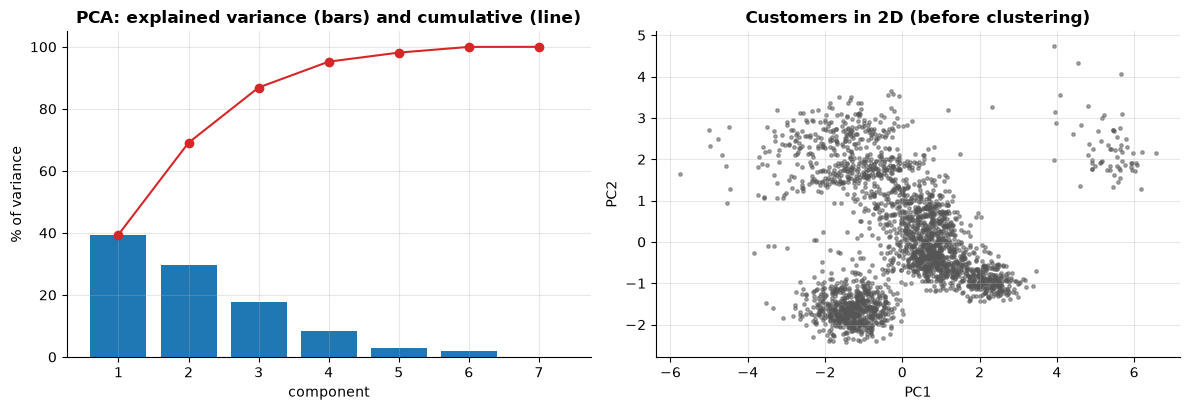

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].bar(range(1, len(explained) + 1), explained * 100, color="#1f77b4")
axes[0].plot(range(1, len(explained) + 1), np.cumsum(explained) * 100, marker="o", color="#d62728")
axes[0].set_xlabel("component"); axes[0].set_ylabel("% of variance"); axes[0].set_title("PCA: explained variance (bars) and cumulative (line)")

axes[1].scatter(pcs[:, 0], pcs[:, 1], s=6, alpha=0.5, color="#555555")
axes[1].set_xlabel("PC1"); axes[1].set_ylabel("PC2"); axes[1].set_title("Customers in 2D (before clustering)")
plt.tight_layout(); plt.show()
savefig(fig, "03_pca")

---
# 7. K-Means from scratch

**K-Means** repeats two steps until nothing changes:

1. **Assign** every point to the nearest centre (smallest squared distance)
2. **Update** every centre to the mean of its points

Two ideas make it reliable:
- **k-means++ initialisation**: choose the first centre at random, then choose each next centre with a probability proportional to its **squared distance** to the nearest centre already chosen (so the centres start spread out).
- **Many restarts** (`n_init`): run it several times from different starts and keep the run with the lowest **inertia** (the sum of squared distances to the centres).

The distance computation uses **broadcasting**: `X[:, None, :] - C[None, :, :]` has shape `(points, centres, features)`.

In [46]:
def kmeans_pp_init(X, k, rng):
    centres = [X[rng.integers(len(X))]]
    for _ in range(1, k):
        d2 = np.min(((X[:, None, :] - np.array(centres)[None, :, :]) ** 2).sum(axis=2), axis=1)      # distance to the nearest chosen centre
        centres.append(X[rng.choice(len(X), p=d2 / d2.sum())])
    return np.array(centres)

def kmeans(X, k, n_init=10, max_iter=100, seed=0):
    best = None
    for run in range(n_init):
        rng = np.random.default_rng(seed + run)
        C = kmeans_pp_init(X, k, rng)
        for _ in range(max_iter):
            d2 = ((X[:, None, :] - C[None, :, :]) ** 2).sum(axis=2)          # (points, centres)
            labels = d2.argmin(axis=1)
            new_C = np.array([X[labels == j].mean(axis=0) if (labels == j).any() else X[rng.integers(len(X))] for j in range(k)])
            if np.allclose(new_C, C):
                break
            C = new_C
        d2 = ((X[:, None, :] - C[None, :, :]) ** 2).sum(axis=2)
        labels = d2.argmin(axis=1)
        inertia = d2[np.arange(len(X)), labels].sum()
        if best is None or inertia < best["inertia"]:
            best = {"labels": labels, "centres": C, "inertia": inertia}
    return best

demo = kmeans(X, 5, n_init=3)
print("k=5 inertia:", round(demo["inertia"], 1), "| cluster sizes:", np.bincount(demo["labels"]))

k=5 inertia: 4380.4 | cluster sizes: [654 659 765  66 356]


## 7.1 How many groups? Elbow, silhouette and stability

There is no single right `k`. Three tools, plus common sense:

| Tool | Idea | Look for |
|---|---|---|
| **Elbow** | inertia always falls when k grows | the bend where gains become small |
| **Silhouette** | for every point: how much closer is it to its own cluster than to the next nearest one (-1 to 1) | a high average |
| **Stability** | do different random starts find the same groups? (adjusted Rand index, 1 = identical) | close to 1 |

In [47]:
def silhouette_score_np(X, labels, sample=1200, seed=0):
    """Mean silhouette on a random sample, using one distance matrix and a one-hot membership matrix."""
    rng = np.random.default_rng(seed)
    idx = rng.choice(len(X), min(sample, len(X)), replace=False)
    A, lab = X[idx], labels[idx]
    D = np.sqrt(((A[:, None, :] - A[None, :, :]) ** 2).sum(axis=2))               # (n, n) distances
    ks = np.unique(lab)
    M = (lab[:, None] == ks[None, :]).astype(float)                               # (n, k) membership
    sums = D @ M                                                                  # sum of distances from every point to every cluster
    counts = M.sum(axis=0)
    own = M.argmax(axis=1)
    a = sums[np.arange(len(A)), own] / np.maximum(counts[own] - 1, 1)
    other = sums / counts[None, :]
    other[np.arange(len(A)), own] = np.inf
    b = other.min(axis=1)
    s = (b - a) / np.maximum(a, b)
    return np.where(counts[own] > 1, s, 0).mean()

def adjusted_rand_index(a, b):
    cont = pd.crosstab(a, b).to_numpy()
    comb2 = lambda x: x * (x - 1) / 2
    sum_ij, sum_a, sum_b = comb2(cont).sum(), comb2(cont.sum(axis=1)).sum(), comb2(cont.sum(axis=0)).sum()
    expected = sum_a * sum_b / comb2(cont.sum())
    return (sum_ij - expected) / ((sum_a + sum_b) / 2 - expected)

ks = range(2, 10)
runs = {k: kmeans(X, k, n_init=8, seed=100) for k in ks}
inertia = [runs[k]["inertia"] for k in ks]
sil = [silhouette_score_np(X, runs[k]["labels"]) for k in ks]

# stability: 4 independent single-start runs per k, average pairwise ARI
stability = []
for k in ks:
    labs = [kmeans(X, k, n_init=1, seed=1000 + 17 * r)["labels"] for r in range(4)]
    stability.append(np.mean([adjusted_rand_index(labs[i], labs[j]) for i in range(4) for j in range(i + 1, 4)]))

table = pd.DataFrame({"inertia": inertia, "silhouette": sil, "stability (ARI)": stability}, index=list(ks)).rename_axis("k")
table.round(3)

,inertia,silhouette,stability (ARI)
k,,,
2,12988.863,0.295,0.249
3,9027.987,0.395,1.000
4,6666.390,0.427,0.665
5,4380.421,0.461,0.912
6,3770.110,0.419,0.834
7,3332.273,0.386,0.708
8,3053.038,0.369,0.778
9,2785.993,0.314,0.723


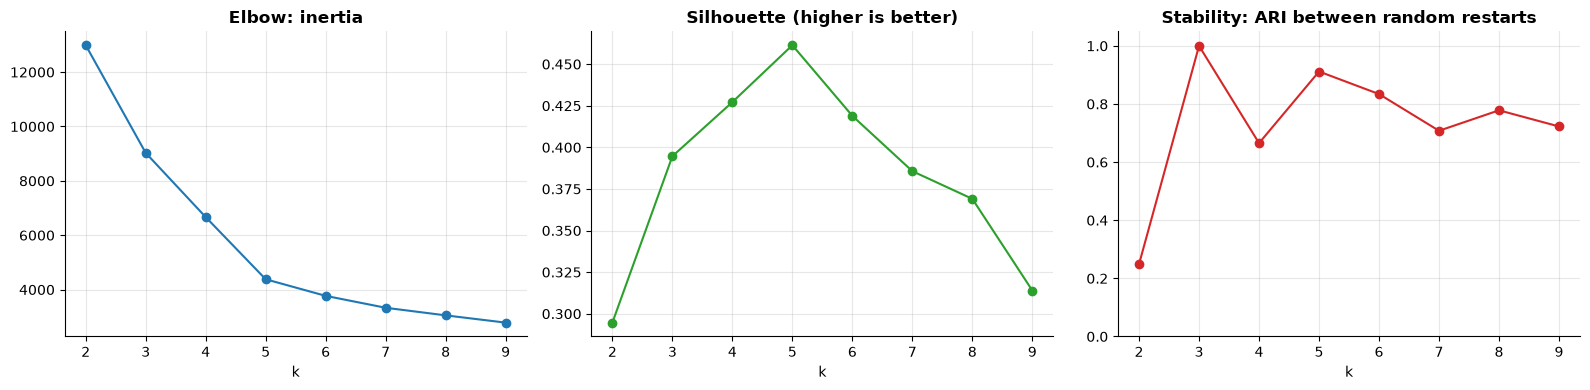

In [48]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(list(ks), inertia, marker="o", color="#1f77b4"); axes[0].set_title("Elbow: inertia"); axes[0].set_xlabel("k")
axes[1].plot(list(ks), sil, marker="o", color="#2ca02c"); axes[1].set_title("Silhouette (higher is better)"); axes[1].set_xlabel("k")
axes[2].plot(list(ks), stability, marker="o", color="#d62728"); axes[2].set_title("Stability: ARI between random restarts"); axes[2].set_xlabel("k")
axes[2].set_ylim(0, 1.05)
plt.tight_layout(); plt.show()
savefig(fig, "04_choose_k")

How to decide: look for a **high silhouette and stable result** at a number of groups the **business can use** (5 to 8 segments is manageable, 2 is too coarse to act on and 20 is too many). The final choice is a mix of statistics and judgement, so we write down the reasoning.

> A common trap: the **highest silhouette** is often at a small `k` (2, 3 or 4), because a few big, obviously different blobs are easy to separate. If such a cluster mixes very different customers (for example champions and wholesale buyers), it is useless for marketing. In this data `k = 5` also has the best silhouette, but do not count on luck: always **read the profiles** of the clusters, whatever the score says. Statistics suggest, **the business decides**.

In [49]:
# A transparent rule. Marketing needs enough groups to act on (at least 5) but not too many (at most 8).
# Among k = 5..8 take the highest silhouette, and prefer results that are reasonably stable (ARI >= 0.7).
cand = table.loc[5:8]
ok = cand[cand["stability (ARI)"] >= 0.7]
K = int((ok if len(ok) else cand)["silhouette"].idxmax())
print("chosen k =", K)
print(table.loc[K].round(3).to_dict())
print("(k = 2, 3 or 4 would be too coarse to act on: they mix very different customers in one group)")

final = runs[K]
cust["cluster"] = final["labels"]
cust["cluster"].value_counts().sort_index().to_frame("customers").T

chosen k = 5
{'inertia': 4380.421, 'silhouette': 0.461, 'stability (ARI)': 0.912}
(k = 2, 3 or 4 would be too coarse to act on: they mix very different customers in one group)


cluster,0,1,2,3,4
customers,765,654,66,659,356


---
# 8. Understand and name the segments

A cluster number means nothing to the marketing team. We describe each cluster by its **average behaviour**, and compare it with the overall average (as z-scores), then give it a business name.

In [50]:
prof = cust.groupby("cluster").agg(
    customers=("frequency", "size"), recency_days=("recency_days", "median"), frequency=("frequency", "median"),
    monetary=("monetary", "median"), avg_order_value=("avg_order_value", "median"), tenure_days=("tenure_days", "median"),
    sale_share=("sale_share", "mean"), avg_units=("avg_units_per_order", "median"), cancel_rate=("cancel_rate", "mean"),
)
prof["share_of_customers_%"] = prof["customers"] / prof["customers"].sum() * 100
prof["share_of_revenue_%"] = cust.groupby("cluster")["net_value"].sum() / cust["net_value"].sum() * 100
prof.round(1)

,customers,recency_days,frequency,monetary,avg_order_value,tenure_days,sale_share,avg_units,cancel_rate,share_of_customers_%,share_of_revenue_%
cluster,,,,,,,,,,,
0,765,16.0,14.0,62433.0,4607.1,349.0,0.1,4.8,0.0,30.6,59.9
1,654,53.0,12.0,9298.0,789.8,314.5,0.6,2.4,0.0,26.2,5.6
2,66,64.0,4.0,374552.0,98517.6,289.5,0.1,176.5,0.0,2.6,22.2
3,659,258.0,4.0,15972.0,3990.0,340.0,0.0,4.5,0.0,26.4,10.7
4,356,17.0,1.0,3654.0,2380.0,33.0,0.0,3.7,0.0,14.2,1.6


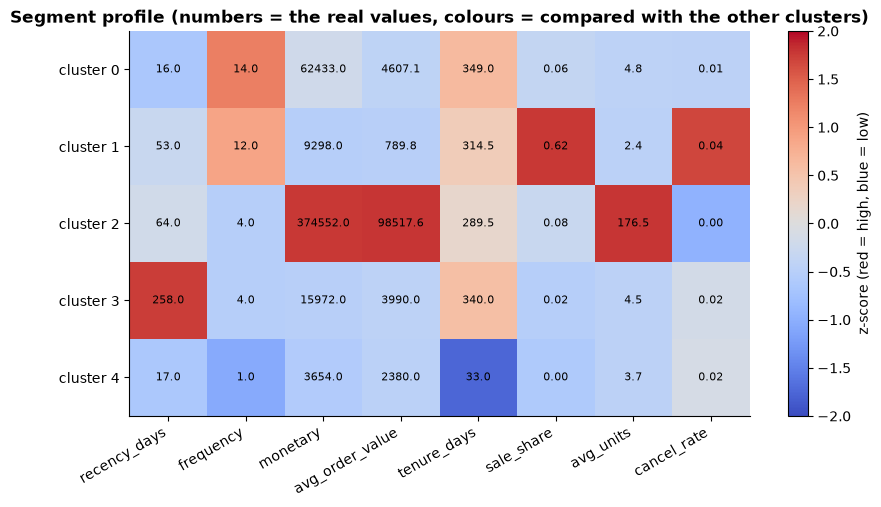

In [51]:
# Heatmap of the profile: z-score of every cluster median against all customers
cols = ["recency_days", "frequency", "monetary", "avg_order_value", "tenure_days", "sale_share", "avg_units", "cancel_rate"]
z = (prof[cols] - prof[cols].mean()) / prof[cols].std()

fig, ax = plt.subplots(figsize=(10, 0.7 * len(z) + 1.5))
im = ax.imshow(z.to_numpy(), cmap="coolwarm", vmin=-2, vmax=2, aspect="auto")
ax.set_xticks(range(len(cols))); ax.set_xticklabels(cols, rotation=30, ha="right")
ax.set_yticks(range(len(z))); ax.set_yticklabels([f"cluster {i}" for i in z.index])
for i in range(z.shape[0]):
    for j in range(z.shape[1]):
        ax.text(j, i, f"{prof[cols].iloc[i, j]:.1f}" if cols[j] not in ("sale_share", "cancel_rate") else f"{prof[cols].iloc[i, j]:.2f}",
                ha="center", va="center", fontsize=8)
ax.grid(False); fig.colorbar(im, ax=ax, label="z-score (red = high, blue = low)")
ax.set_title("Segment profile (numbers = the real values, colours = compared with the other clusters)")
plt.show()
savefig(fig, "05_segment_profile")

## 8.1 Name the segments with transparent rules

We read the table and give each cluster a name from simple rules (so the names are reproducible). **Always read the profile yourself and check the names make sense.**

In [52]:
def name_cluster(r):
    if r["avg_units"] > 8:
        return "Wholesale buyers"
    if r["tenure_days"] < 90 and r["recency_days"] < 60:
        return "New customers"
    if r["recency_days"] > 150 and r["frequency"] <= 1.5:
        return "One-time / lost"
    if r["recency_days"] > 150:
        return "At risk (gone quiet)"
    if r["sale_share"] > 0.35 and r["avg_order_value"] < prof["avg_order_value"].median():
        return "Bargain hunters"
    if r["frequency"] >= prof["frequency"].quantile(0.75) and r["monetary"] >= prof["monetary"].quantile(0.75):
        return "Champions"
    return "Loyal regulars"

names = prof.apply(name_cluster, axis=1)
# if two clusters got the same name, add their number so they stay distinguishable
dup = names.duplicated(keep=False)
names = names.where(~dup, names + " (" + names.index.astype(str) + ")")
cust["segment"] = cust["cluster"].map(names)

pd.DataFrame({"segment": names, "customers": prof["customers"], "median recency": prof["recency_days"], "median frequency": prof["frequency"],
              "median spend": prof["monetary"].round(0), "revenue share %": prof["share_of_revenue_%"].round(1)})

,segment,customers,median recency,median frequency,median spend,revenue share %
cluster,,,,,,
0,Champions,765,16.0,14.0,62433.0,59.9
1,Bargain hunters,654,53.0,12.0,9298.0,5.6
2,Wholesale buyers,66,64.0,4.0,374552.0,22.2
3,At risk (gone quiet),659,258.0,4.0,15972.0,10.7
4,New customers,356,17.0,1.0,3654.0,1.6


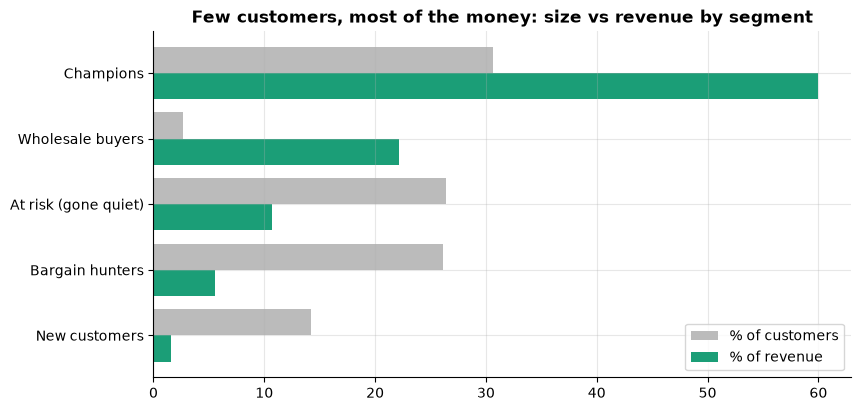

In [53]:
# Chart: size of each segment vs the revenue it brings
seg = cust.groupby("segment").agg(customers=("frequency", "size"), revenue=("net_value", "sum"))
seg["customers_%"] = seg["customers"] / seg["customers"].sum() * 100
seg["revenue_%"] = seg["revenue"] / seg["revenue"].sum() * 100
seg = seg.sort_values("revenue_%")

fig, ax = plt.subplots(figsize=(9, 4.5))
y = np.arange(len(seg))
ax.barh(y + 0.2, seg["customers_%"], height=0.4, color="#bbbbbb", label="% of customers")
ax.barh(y - 0.2, seg["revenue_%"], height=0.4, color="#1b9e77", label="% of revenue")
ax.set_yticks(y); ax.set_yticklabels(seg.index); ax.legend()
ax.set_title("Few customers, most of the money: size vs revenue by segment")
plt.show()
savefig(fig, "06_segment_size_vs_revenue")

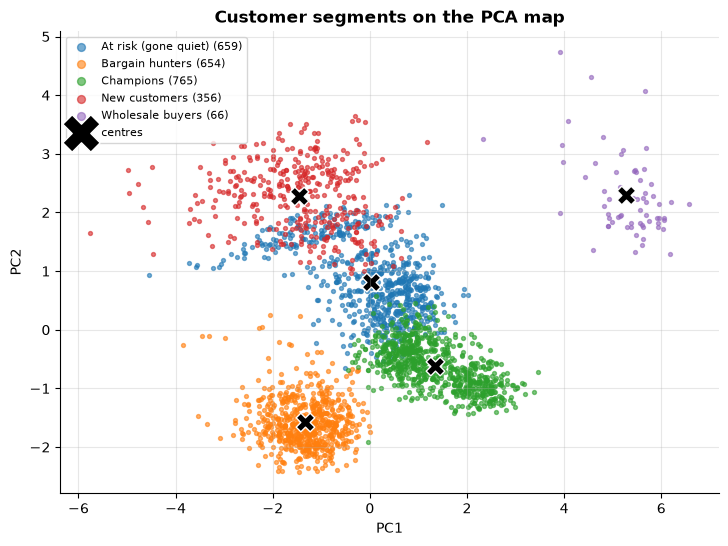

In [54]:
# The clusters on the 2D PCA map
fig, ax = plt.subplots(figsize=(8.5, 6))
for name in sorted(cust["segment"].unique()):
    m = (cust["segment"] == name).to_numpy()
    ax.scatter(pcs[m, 0], pcs[m, 1], s=8, alpha=0.6, label=f"{name} ({m.sum()})")
C2 = (final["centres"] - X.mean(axis=0)) @ Vt[:2].T                                     # centres on the same 2D map
ax.scatter(C2[:, 0], C2[:, 1], marker="X", s=180, color="black", edgecolor="white", label="centres")
ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.legend(fontsize=8, markerscale=2)
ax.set_title("Customer segments on the PCA map")
plt.show()
savefig(fig, "07_segments_pca_map")

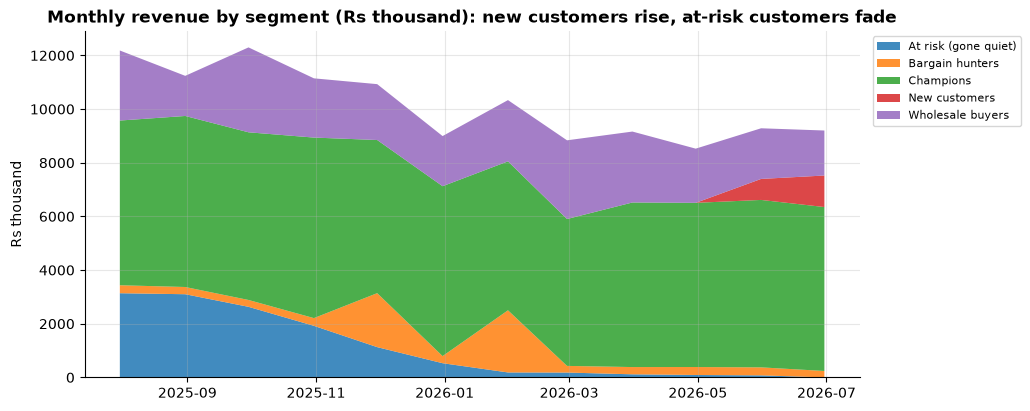

In [55]:
# Time view: monthly revenue by segment (do the names tell the right story?)
labelled = purchases.merge(cust[["segment"]], left_on="customer_id", right_index=True, how="inner", validate="many_to_one")
timeline = labelled.groupby([pd.Grouper(key="invoice_date", freq="ME"), "segment"])["revenue"].sum().unstack(fill_value=0) / 1e3

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.stackplot(timeline.index, timeline.T.to_numpy(), labels=timeline.columns, alpha=0.85)
ax.set_title("Monthly revenue by segment (Rs thousand): new customers rise, at-risk customers fade")
ax.set_ylabel("Rs thousand"); ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
plt.show()
savefig(fig, "08_revenue_timeline_by_segment")

The timeline is a **sanity check of the names**: a segment called "at risk" should have revenue early in the year and little now, and "new customers" the opposite. If the picture contradicts the name, rename or re-cluster.

# 9. Compare with the classic RFM-score method

Marketing teams often use **quintile scores** instead of clustering: each customer gets 1 to 5 points on R, F and M (5 = best), and rules turn the three scores into segments. It is simple and easy to explain. Let us build it and compare.

In [56]:
rfm = cust[["recency_days", "frequency", "monetary"]].copy()
rfm["R"] = pd.qcut(rfm["recency_days"].rank(method="first"), 5, labels=[5, 4, 3, 2, 1]).astype(int)      # recent = high score
rfm["F"] = pd.qcut(rfm["frequency"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["M"] = pd.qcut(rfm["monetary"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)

def rfm_segment(r):
    if r["R"] >= 4 and r["F"] >= 4:
        return "Champions"
    if r["R"] >= 3 and r["F"] >= 3:
        return "Loyal"
    if r["R"] >= 4 and r["F"] <= 2:
        return "New / promising"
    if r["R"] <= 2 and r["F"] >= 3:
        return "At risk"
    if r["R"] <= 2 and r["F"] <= 2:
        return "Lost / hibernating"
    return "Needs attention"

rfm["rfm_segment"] = rfm.apply(rfm_segment, axis=1)
cust["rfm_segment"] = rfm["rfm_segment"]
rfm["rfm_segment"].value_counts().to_frame("customers")

,customers
rfm_segment,
Champions,566
Lost / hibernating,564
Loyal,498
At risk,436
New / promising,281
Needs attention,155


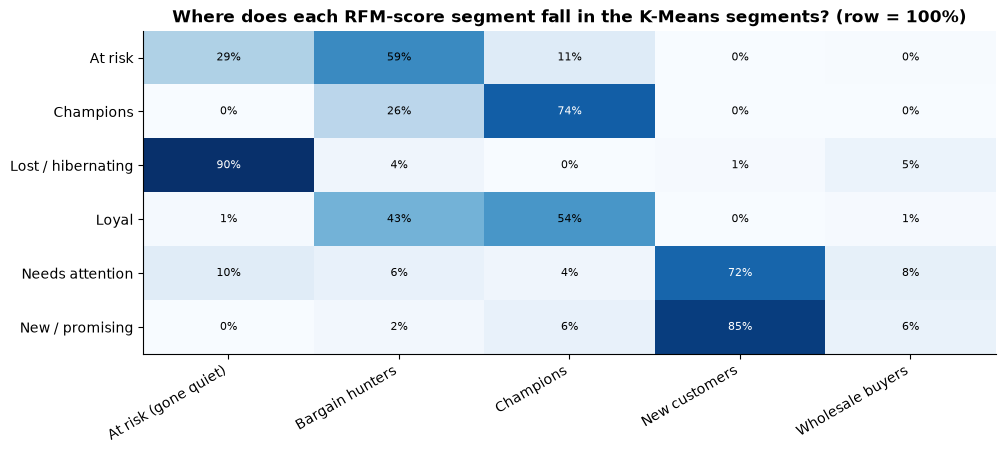

In [57]:
# How do the two methods relate? (crosstab, normalised by the rows of the RFM method)
ct = pd.crosstab(cust["rfm_segment"], cust["segment"], normalize="index") * 100

fig, ax = plt.subplots(figsize=(11, 4.2))
im = ax.imshow(ct.to_numpy(), cmap="Blues", aspect="auto")
ax.set_xticks(range(ct.shape[1])); ax.set_xticklabels(ct.columns, rotation=30, ha="right")
ax.set_yticks(range(ct.shape[0])); ax.set_yticklabels(ct.index)
for i in range(ct.shape[0]):
    for j in range(ct.shape[1]):
        ax.text(j, i, f"{ct.iloc[i, j]:.0f}%", ha="center", va="center", color="black" if ct.iloc[i, j] < 60 else "white", fontsize=8)
ax.grid(False); ax.set_title("Where does each RFM-score segment fall in the K-Means segments? (row = 100%)")
plt.show()
savefig(fig, "09_rfm_vs_kmeans")

**Reading the heatmap:** where a row is concentrated in one column, both methods agree. Where a row is spread out, K-Means separated customers that RFM scores put together (because it also used order value, tenure and sale behaviour).

| | RFM scores | K-Means |
|---|---|---|
| Easy to explain | yes | needs a profile table |
| Uses | R, F, M only | any number of features |
| Segment sizes | by rules (arbitrary) | by the structure of the data |
| Needs scaling and choosing k | no | yes |
| Good when | a quick, standard report is enough | you want to discover groups you did not think of |

# 10. Sanity check against the hidden truth (only possible because the data is simulated)

In [58]:
tr = truth.set_index("customer_id")["true_segment"].reindex(cust.index)
ari = adjusted_rand_index(cust["cluster"].to_numpy(), tr.to_numpy())
print(f"adjusted Rand index between our clusters and the hidden behaviour types: {ari:.2f}  (1 = identical, 0 = random)")

check = pd.crosstab(cust["segment"], tr, normalize="index").mul(100).round(0)
check

adjusted Rand index between our clusters and the hidden behaviour types: 0.73  (1 = identical, 0 = random)


true_segment,at_risk,bargain,champion,loyal,new,one_time,wholesale
segment,,,,,,,
At risk (gone quiet),71.0,0.0,0.0,11.0,0.0,18.0,0.0
Bargain hunters,0.0,98.0,0.0,1.0,0.0,1.0,0.0
Champions,0.0,0.0,38.0,62.0,0.0,0.0,0.0
New customers,0.0,0.0,0.0,0.0,99.0,1.0,0.0
Wholesale buyers,0.0,0.0,0.0,0.0,0.0,0.0,100.0


K-Means never saw the hidden labels, yet its groups line up with the behaviour types the simulator used (some types look alike and merge, for example loyal and champion customers differ mainly by degree). In real projects you **cannot** do this check, so the earlier tools (silhouette, stability, the timeline and business sense) are what you rely on.

**Say it in an interview:** "I validated the clusters in four ways: silhouette, restart stability with adjusted Rand index, whether the revenue timeline matched the segment names, and agreement with the classic RFM scores. In a simulation I also checked recovery of the true groups."

# 11. From segments to actions (the business value)

Each segment gets an action, a goal and a rough **revenue at stake** under clearly stated assumptions.

In [59]:
ACTIONS = {
    "Champions": ("VIP programme, early access, no discounts (they buy anyway)", "protect"),
    "Loyal regulars": ("Cross-sell other categories, loyalty points", "grow"),
    "New customers": ("Welcome series and a second-order incentive within 30 days", "convert"),
    "At risk (gone quiet)": ("Win-back email with a personal offer", "win back"),
    "One-time / lost": ("Low-cost reactivation only (email), then stop", "cheap try"),
    "Bargain hunters": ("Sale-only campaigns, bundles, free shipping thresholds", "margin care"),
    "Wholesale buyers": ("Account manager, volume pricing, invoice terms", "retain"),
}

RESPONSE_RATE = {"win back": 0.08, "cheap try": 0.03, "convert": 0.20}          # assumed
MARGIN, COST_PER_CONTACT = 0.30, 20                                            # assumed: 30% margin, Rs 20 per contact

plan = seg.copy()
def action_for(segment_name):
    for key, value in ACTIONS.items():
        if segment_name.startswith(key):               # names may carry a number suffix such as "Loyal regulars (3)"
            return value
    return ("review this segment by hand", "")

plan["action"] = [action_for(k)[0] for k in plan.index]
plan["goal"] = [action_for(k)[1] for k in plan.index]
plan["avg_revenue_per_customer"] = (plan["revenue"] / plan["customers"]).round(0)

def campaign_profit(row):
    rate = RESPONSE_RATE.get(row["goal"])
    if rate is None:
        return np.nan
    gain = row["customers"] * rate * row["avg_revenue_per_customer"] * 0.5 * MARGIN          # a responder spends about half of their usual yearly value
    return gain - row["customers"] * COST_PER_CONTACT

plan["campaign_profit_Rs"] = plan.apply(campaign_profit, axis=1).round(0)
plan[["customers", "revenue_%", "avg_revenue_per_customer", "goal", "action", "campaign_profit_Rs"]].sort_values("revenue_%", ascending=False)

,customers,revenue_%,avg_revenue_per_customer,goal,action,campaign_profit_Rs
segment,,,,,,
Champions,765,59.942765,94756.0,protect,"VIP programme, early access, no discounts (the...",NaN
Wholesale buyers,66,22.180253,406399.0,retain,"Account manager, volume pricing, invoice terms",NaN
At risk (gone quiet),659,10.693573,19623.0,win back,Win-back email with a personal offer,141999.0
Bargain hunters,654,5.583150,10324.0,margin care,"Sale-only campaigns, bundles, free shipping th...",NaN
New customers,356,1.600260,5436.0,convert,Welcome series and a second-order incentive wi...,50936.0


The profit column is an **estimate under assumptions** (response rates, margin, how much a responder spends). The point is the **method**: segment, assign an action, estimate value, and then **A/B test** the campaign to measure the real response (see project 5).

# 12. Save the deliverables

In [60]:
out = cust.reset_index()[["customer_id", "segment", "cluster", "rfm_segment", "recency_days", "frequency", "monetary", "avg_order_value", "tenure_days", "sale_share", "net_value"]]
out.to_csv(DATA / "customer_segments.csv", index=False)
prof.assign(segment=names).round(2).to_csv(DATA / "segment_profile.csv")
cust.to_csv(DATA / "customer_features.csv")

card = {
    "method": "K-Means (NumPy, k-means++, 8 restarts) on log-transformed, standardised features",
    "features": FEATURES, "log_features": LOG_FEATURES, "k": int(K),
    "silhouette": round(float(table.loc[K, "silhouette"]), 3), "stability_ari": round(float(table.loc[K, "stability (ARI)"]), 3),
    "scaler_mean": {k: round(float(v), 4) for k, v in mean.items()}, "scaler_std": {k: round(float(v), 4) for k, v in std.items()},
    "centres_standardised": np.round(final["centres"], 4).tolist(),
}
(DATA / "model_card.json").write_text(json.dumps(card, indent=2))
print(out.head(5))

   customer_id               segment  cluster         rfm_segment  recency_days  frequency  monetary  avg_order_value  tenure_days  sale_share  \
0        10026  At risk (gone quiet)        3  Lost / hibernating           320          4   38851.0      9712.750000          336    0.000000   
1        10027  At risk (gone quiet)        3  Lost / hibernating           229          6   37457.0      6242.833333          338    0.000000   
2        10043             Champions        0           Champions             1         17  125221.0      7365.941176          344    0.058824   
3        10074  At risk (gone quiet)        3  Lost / hibernating           233          7   21067.0      3009.571429          360    0.000000   
4        10089  At risk (gone quiet)        3  Lost / hibernating           269          3   20913.0      6971.000000          357    0.000000   

   net_value  
0    38851.0  
1    37457.0  
2   125221.0  
3    21067.0  
4    20913.0  


In [61]:
# Scoring a NEW customer with the saved model: standardise with the saved mean/std, then take the nearest centre
new_customer = pd.Series({"recency_days": 12, "frequency": 9, "monetary": 38000, "avg_order_value": 4200,
                          "avg_units_per_order": 5.0, "tenure_days": 300, "sale_share": 0.1})
z_new = new_customer[FEATURES].copy()
z_new[LOG_FEATURES] = np.log1p(z_new[LOG_FEATURES])
z_new = (z_new - mean) / std
nearest = int(((final["centres"] - z_new.to_numpy()) ** 2).sum(axis=1).argmin())
print("this customer belongs to cluster", nearest, "->", names[nearest])

this customer belongs to cluster 0 -> Champions


---
# 13. Summary, resume bullets, interview questions

In [62]:
top = seg.sort_values("revenue_%", ascending=False).iloc[0]
print("RESULTS")
print(f"  {len(cust)} registered customers segmented into {K} groups (silhouette {table.loc[K, 'silhouette']:.2f}, stability ARI {table.loc[K, 'stability (ARI)']:.2f})")
print(f"  top 20% of customers = {top20:.0f}% of revenue | biggest revenue segment: {top.name} ({top['revenue_%']:.0f}% of revenue from {top['customers_%']:.0f}% of customers)")
print(f"  agreement with the hidden behaviour types (simulation only): ARI {ari:.2f}")

print("\nRESUME BULLETS (use your own numbers)")
print(f"- Segmented {len(cust):,} e-commerce customers from 75,000+ messy transaction rows: handled cancellations, guest checkouts, free items and typing errors, and engineered RFM, order-value, tenure and sale-behaviour features with pandas.")
print(f"- Implemented K-Means (k-means++, restarts), PCA via SVD, silhouette score and adjusted Rand index from scratch in NumPy; selected k={K} using silhouette and restart stability.")
print(f"- Translated segments into actions and revenue-at-stake estimates; found that the top 20% of customers generate {top20:.0f}% of revenue.")

RESULTS
  2500 registered customers segmented into 5 groups (silhouette 0.46, stability ARI 0.91)
  top 20% of customers = 74% of revenue | biggest revenue segment: Champions (60% of revenue from 31% of customers)
  agreement with the hidden behaviour types (simulation only): ARI 0.73

RESUME BULLETS (use your own numbers)
- Segmented 2,500 e-commerce customers from 75,000+ messy transaction rows: handled cancellations, guest checkouts, free items and typing errors, and engineered RFM, order-value, tenure and sale-behaviour features with pandas.
- Implemented K-Means (k-means++, restarts), PCA via SVD, silhouette score and adjusted Rand index from scratch in NumPy; selected k=5 using silhouette and restart stability.
- Translated segments into actions and revenue-at-stake estimates; found that the top 20% of customers generate 74% of revenue.


## Likely interview questions about this project

**1. Why do you transform and scale features before K-Means?**
K-Means uses Euclidean distance, so a feature with a large range (total spend in rupees) would dominate one with a small range (sale share). Skewed features are log-transformed so a few huge customers do not create their own clusters, then every feature is standardised.

**2. How do you choose k?**
Elbow, silhouette and stability across restarts, plus business usability. No single metric decides.

**3. What does the silhouette score measure?**
For each point `(b - a) / max(a, b)` where `a` is the mean distance to its own cluster and `b` the mean distance to the nearest other cluster. Near 1: well separated; near 0: on the border; negative: probably in the wrong cluster.

**4. Why k-means++ and several restarts?**
K-Means finds a local minimum that depends on the starting centres. k-means++ spreads the starting centres, and restarts keep the best inertia.

**5. How would you know the clusters are real and not noise?**
Stability (ARI between restarts), silhouette, whether profiles are different and interpretable, whether the timeline matches the story, and ideally whether segments behave differently in an A/B test.

**6. What are the weaknesses of K-Means?**
It assumes roughly round clusters of similar size, is sensitive to outliers and scale, needs k in advance, and results depend on the features chosen. Alternatives: Gaussian mixtures, hierarchical clustering, DBSCAN.

**7. RFM scores or K-Means?**
RFM scores are quick and easy for marketing to explain. K-Means can use more features and finds structure automatically. I built both and compared them with a crosstab.

**8. How do you deal with cancellations and guest customers?**
Cancellations stay as negative revenue and give a cancel rate per customer. Guest checkouts cannot be grouped, so they are excluded from the clustering and reported separately.

**9. How would you use the segments in production?**
Re-score customers every month (the saved means, standard deviations and centres give a nearest-centre rule), watch segment sizes drift, and measure each campaign with an A/B test.

**10. What is PCA doing here and does it change the clusters?**
It is only used for the 2D picture. Clustering is done on the standardised features. PCA keeps the directions with the most variance, and the explained variance tells how much of the 7D structure the picture shows.

## Extension ideas

1. Cluster with a **Gaussian mixture** (EM in NumPy) and compare.
2. Add **product-level features** (share of electronics, average discount) and see whether the segments change.
3. Predict **next-month purchase** per segment (connect to project 1).
4. Build a **Streamlit** page where marketing selects a segment and downloads the customer list (`21_streamlit`).
5. Run the A/B analysis of a win-back email with project 5's method.

## Revision sheet: functions you practised

| Library | Functions and ideas |
|---|---|
| **pandas** | `drop_duplicates`, `to_datetime(format=)`, boolean filters, `str.strip/title`, `merge(validate=)`, `groupby().agg(named)`, `diff` within groups, `pivot_table`, `idxmax(axis=1)`, `qcut`, `crosstab(normalize=)`, `Grouper`, `stackplot` data via `unstack` |
| **NumPy** | broadcasting `X[:, None, :] - C[None, :, :]`, `argmin`, `bincount`, `linalg.svd`, `cumsum`, `random.default_rng().choice(p=...)`, one-hot via `==`, `@`, `where`, `allclose`, `unique` |
| **Matplotlib** | `hist`, `scatter`, `barh`, `stackplot`, `imshow` with annotated text, `axvline`, twin metrics in subplots, Pareto curve |
| **ML ideas** | skew and log transform, standardisation, PCA, K-Means, k-means++, inertia, silhouette, adjusted Rand index, cluster profiling and naming, RFM scoring |